# GPU-Optimized Autoregressive Text Generation
## Simple RNN, Bidirectional RNN, LSTM, and GRU on Nietzsche's philosophical prose

**Student:** Tanay Aggarwal  
**Registration number:** 230911278  
**Module:** ICT4403 - Foundations of Generative AI, Assignment 2

This notebook is an executable experimental report. It trains four recurrent architectures under comparable conditions, evaluates predictive and generative quality, and records the accelerator used by the verified run.

## 1. Research question and experimental controls

**Question:** Which recurrent architecture provides the best balance of held-out predictive performance, computational efficiency, and qualitative generation on an atypical philosophical corpus?

The recurrent architecture is the independent variable. Vocabulary, sequence length, chronological splits, embedding/hidden dimensions, optimizer, learning-rate schedule, batch size, epoch budget, early stopping, gradient clipping, prompts, and sampling temperatures are controlled. Outcomes are loss, perplexity, top-1/top-5 accuracy, time, parameter count, diversity, repetition, prompt retention, and qualitative coherence.

Perplexity is $\exp(\text{mean negative log likelihood})$. It is the primary criterion because autoregressive models estimate a distribution, whereas accuracy credits only the single highest-probability word.

In [1]:
from pathlib import Path
from collections import Counter
from contextlib import nullcontext
import json, math, random, re, subprocess, time, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

SEED = 4403
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Native PyTorch recurrent kernels are optimized by cuDNN on CUDA.
if torch.cuda.is_available():
    BACKEND, DEVICE = 'cuda', torch.device('cuda')
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision('high')
else:
    BACKEND, DEVICE = 'cpu', torch.device('cpu')
USE_AMP = BACKEND == 'cuda'

CFG = {
    'sequence_length': 30, 'stride': 2, 'min_frequency': 2, 'max_vocab': 8000,
    'embedding_dim': 128, 'hidden_dim': 192, 'dropout': 0.25,
    'batch_size': 512, 'learning_rate': 2.5e-3, 'weight_decay': 1e-4,
    'label_smoothing': 0.05, 'epochs': 12, 'patience': 3, 'gradient_clip': 1.0,
    'tuning_epochs': 6, 'tuning_patience': 2,
    'generation_tokens': 70, 'temperatures': [0.5, 1.0, 1.5]
}
for folder in ['data', 'artifacts', 'checkpoints']: Path(folder).mkdir(exist_ok=True)
try:
    gpu_name = subprocess.check_output(['nvidia-smi', '--query-gpu=name', '--format=csv,noheader'], text=True).strip().splitlines()[0]
except Exception: gpu_name = 'not reported'
print(f'PyTorch={torch.__version__} | backend={BACKEND} | device={DEVICE} | physical GPU={gpu_name}')
print(CFG)

PyTorch=2.13.0+cu126 | backend=cuda | device=cuda | physical GPU=NVIDIA GeForce RTX 3050 Laptop GPU
{'sequence_length': 30, 'stride': 2, 'min_frequency': 2, 'max_vocab': 8000, 'embedding_dim': 128, 'hidden_dim': 192, 'dropout': 0.25, 'batch_size': 512, 'learning_rate': 0.0025, 'weight_decay': 0.0001, 'label_smoothing': 0.05, 'epochs': 12, 'patience': 3, 'gradient_clip': 1.0, 'tuning_epochs': 6, 'tuning_patience': 2, 'generation_tokens': 70, 'temperatures': [0.5, 1.0, 1.5]}


## 2. Why this dataset?

The [official Keras character-generation example](https://keras.io/examples/generative/lstm_character_level_text_generation/) has used this Nietzsche corpus since 2015, making it a recognized recurrent text-generation comparison dataset. It is atypical relative to common news/Wikipedia benchmarks: philosophical prose contains abstract concepts, rhetorical questions, aphorisms, long dependencies, unusual punctuation, and emphatic capitalization. Those properties make next-word prediction and coherent continuation genuinely challenging.

The local file is the official Keras-hosted corpus. If absent, the notebook downloads it from `https://s3.amazonaws.com/text-datasets/nietzsche.txt`. Unicode is normalized, line breaks are collapsed, and text is lowercased. Words, contractions, numbers, and sentence punctuation are preserved.

In [2]:
DATA_URL = 'https://s3.amazonaws.com/text-datasets/nietzsche.txt'
DATA_PATH = Path('data/nietzsche.txt')
if not DATA_PATH.exists():
    response = requests.get(DATA_URL, timeout=60); response.raise_for_status(); DATA_PATH.write_bytes(response.content)
raw_text = DATA_PATH.read_text(encoding='utf-8-sig')
clean_text = unicodedata.normalize('NFKC', raw_text).replace('’', "'").lower()
clean_text = re.sub(r'\s+', ' ', clean_text).strip()
tokens = re.findall(r"[a-z]+(?:'[a-z]+)?|\d+|[.!?,;:]", clean_text)
freq = Counter(tokens)
sentences = [s.strip() for s in re.split(r'[.!?]+', clean_text) if s.strip()]
sentence_lengths = [len(re.findall(r"[a-z]+(?:'[a-z]+)?", s)) for s in sentences]
stats = pd.DataFrame({'Measure':['Characters','Tokens','Unique tokens','Sentences','Mean sentence words','Median sentence words','Hapax tokens'],
                      'Value':[len(clean_text),len(tokens),len(freq),len(sentences),round(np.mean(sentence_lengths),2),round(np.median(sentence_lengths),2),sum(v==1 for v in freq.values())]})
display(stats); print('Most frequent:', freq.most_common(20)); print('Preview:', ' '.join(tokens[:100]))

,Measure,Value
0,Characters,598861.00
1,Tokens,114447.00
2,Unique tokens,10237.00
3,Sentences,3530.00
4,Mean sentence words,28.56
5,Median sentence words,22.00
6,Hapax tokens,4950.00


Most frequent: [(',', 8201), ('the', 6387), ('of', 4634), ('and', 3833), ('to', 2871), ('.', 2787), ('in', 2221), ('is', 2022), ('a', 2017), ('that', 1388), ('it', 1317), ('as', 1279), ('for', 934), ('which', 861), ('be', 771), ('not', 739), ('with', 704), (':', 667), ('he', 660), (';', 627)]
Preview: preface supposing that truth is a woman what then ? is there not ground for suspecting that all philosophers , in so far as they have been dogmatists , have failed to understand women that the terrible seriousness and clumsy importunity with which they have usually paid their addresses to truth , have been unskilled and unseemly methods for winning a woman ? certainly she has never allowed herself to be won ; and at present every kind of dogma stands with sad and discouraged mien if , indeed , it stands at all ! for there are scoffers who


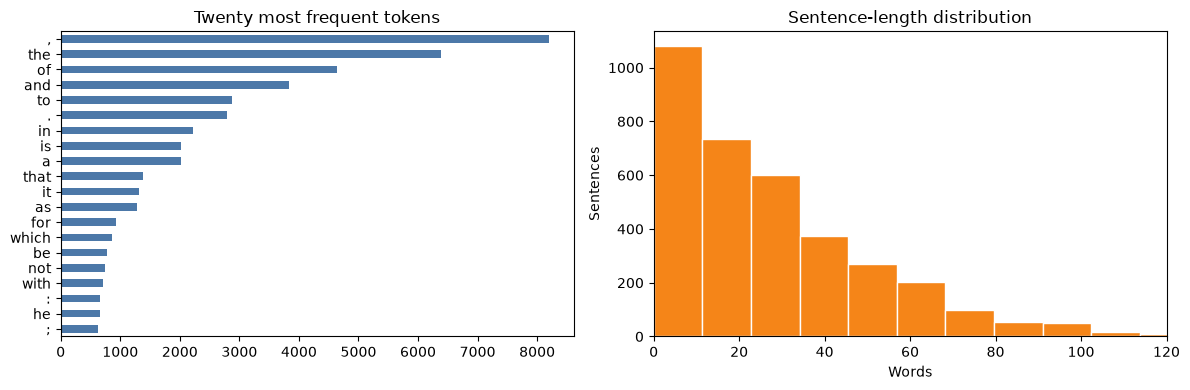

In [3]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
pd.Series(dict(freq.most_common(20))).sort_values().plot.barh(ax=axes[0],color='#4c78a8',title='Twenty most frequent tokens')
axes[1].hist(sentence_lengths,bins=40,color='#f58518',edgecolor='white'); axes[1].set(title='Sentence-length distribution',xlabel='Words',ylabel='Sentences',xlim=(0,120))
plt.tight_layout(); plt.show()

## 3. Autoregressive examples and leakage-resistant splitting

Each sample contains 30 observed tokens and the immediately following target. Vocabulary is learned from corpus frequencies; singleton and out-of-cap tokens become `<unk>`. A chronological 80/10/10 split is used before DataLoader construction. This is stricter than randomly scattering strongly overlapping windows across splits and tests continuation into unseen later text. Stride 2 reduces redundant training examples and GPU time without changing any model's data.

In [4]:
specials = ['<pad>','<unk>']
eligible = [t for t,c in freq.most_common(CFG['max_vocab']-len(specials)) if c >= CFG['min_frequency']]
vocab_tokens = specials + eligible
stoi = {t:i for i,t in enumerate(vocab_tokens)}; itos = {i:t for t,i in stoi.items()}
ids = np.asarray([stoi.get(t,stoi['<unk>']) for t in tokens],dtype=np.int64)
starts = np.arange(0,len(ids)-CFG['sequence_length'],CFG['stride'])
X = np.stack([ids[i:i+CFG['sequence_length']] for i in starts]); y = ids[starts+CFG['sequence_length']]
n=len(X); train_end,val_end=int(.8*n),int(.9*n)
splits={'train':(X[:train_end],y[:train_end]),'validation':(X[train_end:val_end],y[train_end:val_end]),'test':(X[val_end:],y[val_end:])}
pin = BACKEND == 'cuda'
loaders={}
for name,(sx,sy) in splits.items():
    ds=TensorDataset(torch.from_numpy(sx),torch.from_numpy(sy))
    loaders[name]=DataLoader(ds,batch_size=CFG['batch_size'],shuffle=(name=='train'),pin_memory=pin,num_workers=0)
display(pd.DataFrame([{'Split':k,'Sequences':len(v[0]),'Percentage':100*len(v[0])/n} for k,v in splits.items()]))
print(f'Vocabulary={len(stoi):,}; OOV rate={(ids==stoi["<unk>"]).mean():.2%}; examples={n:,}')
print('Context:', ' '.join(itos[int(i)] for i in X[100])); print('Target:',itos[int(y[100])])

,Split,Sequences,Percentage
0,train,45767,79.999650
1,validation,5721,10.000175
2,test,5721,10.000175


Vocabulary=5,289; OOV rate=4.33%; examples=57,209
Context: some popular superstition of immemorial time such as the soul superstition , which , in the form of subject and ego superstition , has not yet ceased doing mischief :
Target: perhaps


## 4. Native PyTorch recurrent architectures

The implementation uses PyTorch's native `nn.RNN`, `nn.LSTM`, and `nn.GRU` modules. On CUDA these dispatch to optimized cuDNN recurrent kernels, avoiding slow Python-level time-step loops. The bidirectional condition uses `nn.RNN(..., bidirectional=True)`. All models retain the same embedding size, hidden size, input windows, output head, and training protocol for a controlled comparison.

- **Simple RNN:** $h_t=\tanh(W_xx_t+W_hh_{t-1})$.
- **Bidirectional RNN:** independent forward/backward Simple RNNs; their final context states are concatenated. The target is excluded, so there is no target leakage, although this encoder is not causal internally.
- **LSTM:** fused input/forget/candidate/output gates and a persistent cell state.
- **GRU:** fused reset/update/candidate gates with no separate cell state.

Parameter counts are reported because gate count and bidirectionality naturally change capacity.

In [5]:
class RecurrentLanguageModel(nn.Module):
    def __init__(self,vocab_size,kind,embedding_dim,hidden_dim,dropout):
        super().__init__(); self.kind=kind; self.bidirectional=kind=='Bidirectional RNN'
        self.embedding=nn.Embedding(vocab_size,embedding_dim,padding_idx=0)
        if kind in ('Simple RNN','Bidirectional RNN'):
            recurrent_cls=nn.RNN
        elif kind=='LSTM': recurrent_cls=nn.LSTM
        else: recurrent_cls=nn.GRU
        self.recurrent=recurrent_cls(embedding_dim,hidden_dim,batch_first=True,bidirectional=self.bidirectional)
        self.dropout=nn.Dropout(dropout)
        self.output=nn.Linear(hidden_dim*(2 if self.bidirectional else 1),vocab_size)
        nn.init.normal_(self.embedding.weight,mean=0.0,std=0.02)
        nn.init.xavier_uniform_(self.output.weight); nn.init.zeros_(self.output.bias)
        for name,param in self.recurrent.named_parameters():
            if 'weight_ih' in name: nn.init.xavier_uniform_(param)
            elif 'weight_hh' in name: nn.init.orthogonal_(param)
            elif 'bias' in name: nn.init.zeros_(param)

    def forward(self,x):
        _,state=self.recurrent(self.embedding(x))
        hidden=state[0] if self.kind=='LSTM' else state
        representation=torch.cat([hidden[-2],hidden[-1]],dim=1) if self.bidirectional else hidden[-1]
        return self.output(self.dropout(representation))

model_names=['Simple RNN','Bidirectional RNN','LSTM','GRU']
models={n:RecurrentLanguageModel(len(stoi),n,CFG['embedding_dim'],CFG['hidden_dim'],CFG['dropout']).to(DEVICE) for n in model_names}
model_table=pd.DataFrame([{'Model':n,'Parameters':sum(p.numel() for p in m.parameters())} for n,m in models.items()])
display(model_table.style.format({'Parameters':'{:,}'}))

,Model,Parameters
0,Simple RNN,"1,759,593"
1,Bidirectional RNN,"2,836,905"
2,LSTM,"1,945,065"
3,GRU,"1,883,241"


In [6]:
# Accelerator smoke test: forward, backward, optimizer step on one real batch.
smoke_model=models['GRU']; smoke_model.train(); smoke_opt=torch.optim.AdamW(smoke_model.parameters(),lr=1e-4,fused=USE_AMP)
xb,yb=next(iter(loaders['train'])); xb,yb=xb.to(DEVICE),yb.to(DEVICE)
smoke_opt.zero_grad(); smoke_loss=nn.functional.cross_entropy(smoke_model(xb),yb); smoke_loss.backward(); smoke_opt.step()
print(f'GPU smoke test completed on {BACKEND}: loss={float(smoke_loss.detach().cpu()):.4f}, batch={len(yb)}')
# Recreate all models so the controlled experiment starts from seeded fresh weights.
torch.manual_seed(SEED)
models={n:RecurrentLanguageModel(len(stoi),n,CFG['embedding_dim'],CFG['hidden_dim'],CFG['dropout']).to(DEVICE) for n in model_names}

GPU smoke test completed on cuda: loss=8.5734, batch=512


## 5. Optimized and controlled training

Training uses PyTorch's fused CUDA AdamW and automatic mixed precision (AMP) for greater throughput and lower memory use. Mild decoupled weight decay and 0.05 label smoothing regularize the models; validation/test perplexity uses ordinary unsmoothed cross-entropy. Gradients are unscaled before clipping at norm 1.0. Validation plateaus halve the learning rate, and early stopping restores the best checkpoint. Batch size 512 improves accelerator utilization while fitting the 4 GB GPU.

### Validation-only hyperparameter tuning

Each architecture receives the same four-candidate budget. The search varies hidden-state capacity, dropout, learning rate, and weight decay. Every candidate trains for at most six epochs with identical data, initialization seeds, batch size, and stopping rules. Selection minimizes **validation cross-entropy**; the test split is not inspected during tuning. The winning configuration is then reinitialized and trained for the full epoch budget. This nested workflow prevents test-set leakage while allowing architecture-specific optimization.


--- Tuning Simple RNN: 4 validation-only trials ---


Simple RNN         epoch=01 train=6.5800 val=7.0133 ppl=1111.3 lr=2.5e-03


Simple RNN         epoch=02 train=6.5458 val=6.1323 ppl=460.5 lr=2.5e-03


Simple RNN         epoch=03 train=6.0415 val=5.9519 ppl=384.5 lr=2.5e-03


Simple RNN         epoch=04 train=5.9919 val=6.0321 ppl=416.6 lr=2.5e-03


...

GRU                epoch=04 train=5.6084 val=5.7625 ppl=318.2 lr=2.0e-03


GRU                epoch=05 train=5.4067 val=5.7428 ppl=311.9 lr=2.0e-03


GRU                epoch=06 train=5.2289 val=5.7451 ppl=312.7 lr=2.0e-03
  wide         hidden=256 dropout=0.30 lr=2.0e-03 val=5.7428


,Model,candidate,hidden_dim,dropout,learning_rate,weight_decay
0,Simple RNN,regularized,192,0.4,0.0015,0.0003
1,Bidirectional RNN,regularized,192,0.4,0.0015,0.0003
2,LSTM,wide,256,0.3,0.0020,0.0001
3,GRU,wide,256,0.3,0.0020,0.0001


,Model,trial,candidate,hidden_dim,dropout,learning_rate,weight_decay,best_val_loss,best_val_perplexity,epochs_run,tuning_time_seconds
0,Bidirectional RNN,3,regularized,192,0.400000,0.001500,0.000300,5.8397,343.7,6,5.1
1,Bidirectional RNN,2,compact_fast,128,0.300000,0.003000,0.000200,5.8754,356.2,6,5.8
2,Bidirectional RNN,1,baseline,192,0.250000,0.002500,0.000100,5.8940,362.9,5,5.0
3,Bidirectional RNN,4,wide,256,0.300000,0.002000,0.000100,5.9584,387.0,6,6.0
4,GRU,4,wide,256,0.300000,0.002000,0.000100,5.7428,311.9,6,6.8
5,GRU,3,regularized,192,0.400000,0.001500,0.000300,5.7910,327.3,6,10.1
6,GRU,1,baseline,192,0.250000,0.002500,0.000100,5.8214,337.5,6,10.0
7,GRU,2,compact_fast,128,0.300000,0.003000,0.000200,5.9187,371.9,6,4.7
8,LSTM,4,wide,256,0.300000,0.002000,0.000100,5.7692,320.3,6,7.3
9,LSTM,1,baseline,192,0.250000,0.002500,0.000100,5.7749,322.1,6,12.6


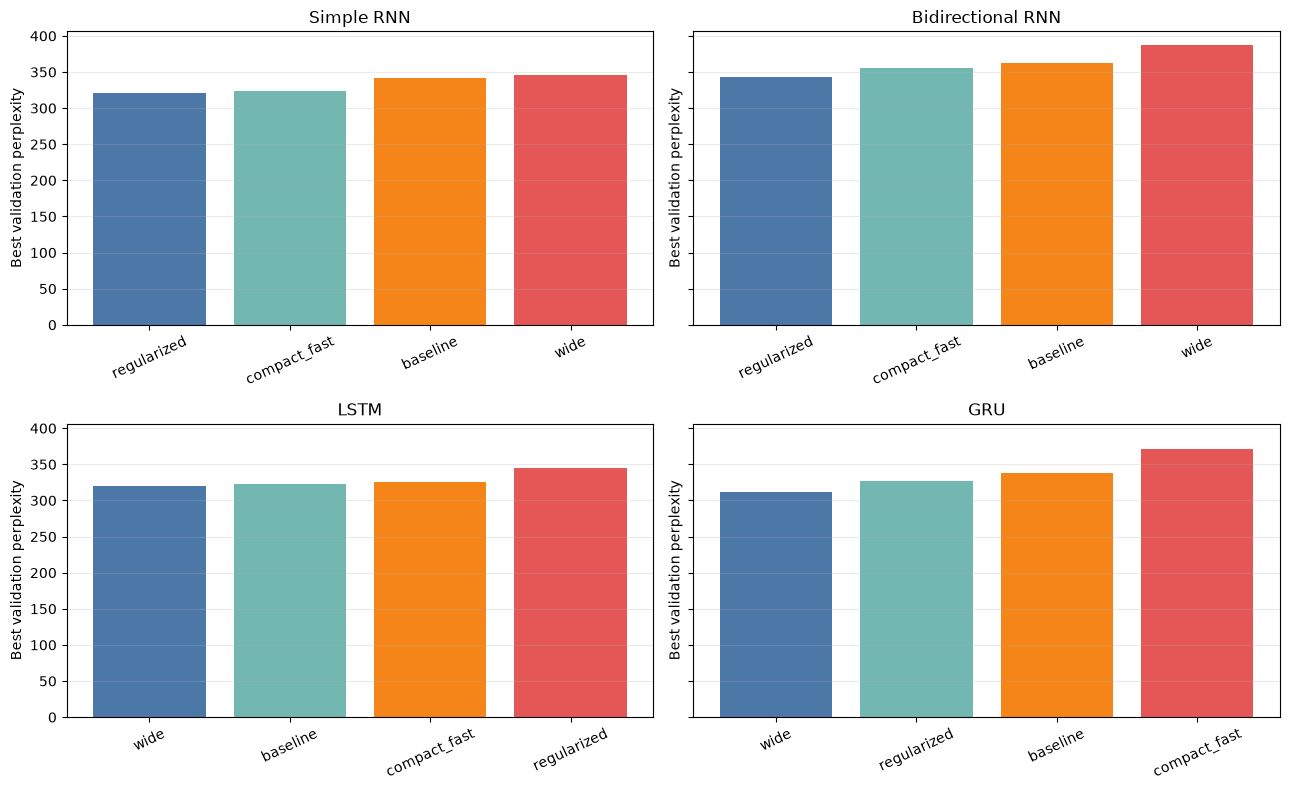


--- Final training Simple RNN on cuda with regularized configuration ---


Simple RNN         epoch=01 train=6.5743 val=6.2417 ppl=513.7 lr=1.5e-03


Simple RNN         epoch=02 train=6.2880 val=6.1304 ppl=459.6 lr=1.5e-03


Simple RNN         epoch=03 train=5.9550 val=5.8889 ppl=361.0 lr=1.5e-03


Simple RNN         epoch=04 train=5.7259 val=5.8356 ppl=342.3 lr=1.5e-03


...

GRU                epoch=05 train=5.4752 val=5.7729 ppl=321.5 lr=2.0e-03


GRU                epoch=06 train=5.3092 val=5.7406 ppl=311.3 lr=2.0e-03


GRU                epoch=07 train=5.1409 val=5.7458 ppl=312.9 lr=2.0e-03


GRU                epoch=08 train=4.9590 val=5.7663 ppl=319.4 lr=2.0e-03
Learning rate reduced to 1.0e-03


GRU                epoch=09 train=4.6991 val=5.7891 ppl=326.7 lr=1.0e-03
Early stopping.


In [7]:
train_criterion=nn.CrossEntropyLoss(label_smoothing=CFG['label_smoothing'])
eval_criterion=nn.CrossEntropyLoss()
def sync():
    if BACKEND=='cuda': torch.cuda.synchronize()
def move(batch): return batch[0].to(DEVICE,non_blocking=(BACKEND=='cuda')),batch[1].to(DEVICE,non_blocking=(BACKEND=='cuda'))

def evaluate(model,loader):
    model.eval(); loss_sum=correct1=correct5=count=0
    with torch.no_grad():
        for batch in loader:
            xb,yb=move(batch); logits=model(xb); b=yb.size(0)
            loss_sum+=float(eval_criterion(logits,yb).cpu())*b; count+=b
            correct1+=int((logits.argmax(1)==yb).sum().cpu())
            correct5+=int((logits.topk(5,dim=1).indices==yb[:,None]).any(1).sum().cpu())
    loss=loss_sum/count
    return {'loss':loss,'perplexity':math.exp(min(loss,20)),'accuracy':correct1/count,'top5_accuracy':correct5/count}

def train_model(model,name,run_cfg,max_epochs,patience,save_checkpoint=False,verbose=True):
    optimizer=torch.optim.AdamW(model.parameters(),lr=run_cfg['learning_rate'],weight_decay=run_cfg['weight_decay'],fused=USE_AMP)
    scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
    history=[]; best_loss=float('inf'); best_state=None; stale=0; plateau=0; sync(); started=time.perf_counter()
    for epoch in range(1,max_epochs+1):
        model.train(); total=seen=0
        for batch in loaders['train']:
            xb,yb=move(batch); optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda',enabled=USE_AMP): loss=train_criterion(model(xb),yb)
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(),CFG['gradient_clip'])
            scaler.step(optimizer); scaler.update(); b=yb.size(0); total+=float(loss.detach().cpu())*b; seen+=b
        val=evaluate(model,loaders['validation'])
        current_lr=optimizer.param_groups[0]['lr']
        row={'epoch':epoch,'train_loss':total/seen,'val_loss':val['loss'],'val_perplexity':val['perplexity'],'learning_rate':current_lr}
        history.append(row)
        if verbose: print(f"{name:18s} epoch={epoch:02d} train={row['train_loss']:.4f} val={row['val_loss']:.4f} ppl={row['val_perplexity']:.1f} lr={row['learning_rate']:.1e}")
        if val['loss']<best_loss-1e-4:
            best_loss=val['loss']; best_state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; stale=0; plateau=0
        else:
            stale+=1; plateau+=1
            if plateau>=2:
                for group in optimizer.param_groups: group['lr']=max(2e-4,group['lr']*0.5)
                plateau=0
                if verbose: print(f"Learning rate reduced to {optimizer.param_groups[0]['lr']:.1e}")
            if stale>=patience:
                if verbose: print('Early stopping.')
                break
    sync(); elapsed=time.perf_counter()-started; model.load_state_dict({k:v.to(DEVICE) for k,v in best_state.items()})
    if save_checkpoint: torch.save(best_state,Path('checkpoints')/f"{name.lower().replace(' ','_')}.pt")
    return pd.DataFrame(history),elapsed,best_loss

search_candidates=[
    {'candidate':'baseline','hidden_dim':192,'dropout':0.25,'learning_rate':2.5e-3,'weight_decay':1e-4},
    {'candidate':'compact_fast','hidden_dim':128,'dropout':0.30,'learning_rate':3.0e-3,'weight_decay':2e-4},
    {'candidate':'regularized','hidden_dim':192,'dropout':0.40,'learning_rate':1.5e-3,'weight_decay':3e-4},
    {'candidate':'wide','hidden_dim':256,'dropout':0.30,'learning_rate':2.0e-3,'weight_decay':1e-4},
]
tuning_rows=[]; selected_configs={}
for name in model_names:
    print(f'\n--- Tuning {name}: {len(search_candidates)} validation-only trials ---')
    for trial,candidate in enumerate(search_candidates,1):
        torch.manual_seed(SEED+trial); torch.cuda.manual_seed_all(SEED+trial)
        candidate_model=RecurrentLanguageModel(len(stoi),name,CFG['embedding_dim'],candidate['hidden_dim'],candidate['dropout']).to(DEVICE)
        trial_history,trial_time,best_val=train_model(candidate_model,name,candidate,CFG['tuning_epochs'],CFG['tuning_patience'])
        tuning_rows.append({'Model':name,'trial':trial,**candidate,'best_val_loss':best_val,'best_val_perplexity':math.exp(best_val),'epochs_run':len(trial_history),'tuning_time_seconds':trial_time})
        print(f"  {candidate['candidate']:12s} hidden={candidate['hidden_dim']:3d} dropout={candidate['dropout']:.2f} lr={candidate['learning_rate']:.1e} val={best_val:.4f}")
        del candidate_model; torch.cuda.empty_cache()
    model_trials=pd.DataFrame(tuning_rows).query('Model == @name')
    winner=model_trials.loc[model_trials.best_val_loss.idxmin()]
    selected_configs[name]={'candidate':str(winner['candidate']),'hidden_dim':int(winner['hidden_dim']),'dropout':float(winner['dropout']),'learning_rate':float(winner['learning_rate']),'weight_decay':float(winner['weight_decay'])}

tuning_results=pd.DataFrame(tuning_rows).sort_values(['Model','best_val_loss']).reset_index(drop=True)
tuned_hyperparameters=pd.DataFrame([{'Model':name,**cfg} for name,cfg in selected_configs.items()])
tuning_results.to_csv('artifacts/tuning_trials.csv',index=False); tuned_hyperparameters.to_csv('artifacts/tuned_hyperparameters.csv',index=False)
display(tuned_hyperparameters); display(tuning_results.style.format({'best_val_loss':'{:.4f}','best_val_perplexity':'{:.1f}','tuning_time_seconds':'{:.1f}'}))
fig,axes=plt.subplots(2,2,figsize=(13,8),sharey=True)
for ax,name in zip(axes.flat,model_names):
    subset=tuning_results[tuning_results.Model==name].sort_values('best_val_perplexity')
    ax.bar(subset.candidate,subset.best_val_perplexity,color=['#4c78a8','#72b7b2','#f58518','#e45756']); ax.set(title=name,ylabel='Best validation perplexity'); ax.tick_params(axis='x',rotation=25); ax.grid(axis='y',alpha=.25)
plt.tight_layout(); plt.savefig('artifacts/tuning_validation.png',dpi=180,bbox_inches='tight'); plt.show()

histories={}; training_times={}; models={}
for name in model_names:
    cfg=selected_configs[name]; torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    models[name]=RecurrentLanguageModel(len(stoi),name,CFG['embedding_dim'],int(cfg['hidden_dim']),float(cfg['dropout'])).to(DEVICE)
    print(f"\n--- Final training {name} on {BACKEND} with {cfg['candidate']} configuration ---")
    histories[name],training_times[name],_=train_model(models[name],name,cfg,CFG['epochs'],CFG['patience'],save_checkpoint=True)

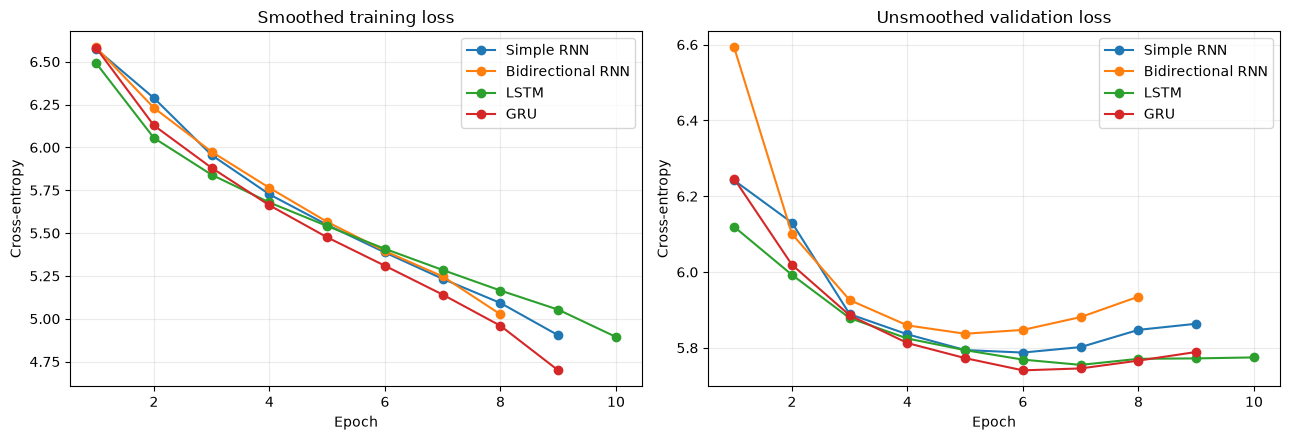

In [8]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for name,h in histories.items():
    axes[0].plot(h.epoch,h.train_loss,marker='o',label=name); axes[1].plot(h.epoch,h.val_loss,marker='o',label=name)
for ax,title in zip(axes,['Smoothed training loss','Unsmoothed validation loss']): ax.set(title=title,xlabel='Epoch',ylabel='Cross-entropy'); ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); plt.savefig('artifacts/training_curves.png',dpi=180,bbox_inches='tight'); plt.show()

## 6. Held-out quantitative comparison

The test split is evaluated only after validation-based checkpoint selection. Lower loss/perplexity is better; higher accuracy is better. Runtime includes training and validation but excludes preprocessing. Parameter count and accelerator are shown so efficiency claims remain auditable.

,Model,loss,perplexity,accuracy,top5_accuracy,training_time_seconds,epochs_run,parameters,configuration,hidden_dim,dropout,learning_rate,weight_decay,backend
0,GRU,5.6738,291.15,14.65%,31.03%,10.3,9,"2,332,713",wide,256,0.300000,0.002000,0.000100,cuda
1,LSTM,5.6869,294.99,14.63%,31.81%,12.1,10,"2,431,529",wide,256,0.300000,0.002000,0.000100,cuda
2,Simple RNN,5.7150,303.37,14.19%,30.96%,6.7,9,"1,759,593",regularized,192,0.400000,0.001500,0.000300,cuda
3,Bidirectional RNN,5.7583,316.80,13.48%,31.06%,7.1,8,"2,836,905",regularized,192,0.400000,0.001500,0.000300,cuda


,Model,tuned_perplexity,baseline_perplexity,absolute_change,percent_change
0,GRU,291.15,288.48,+2.66,+0.92%
1,LSTM,294.99,296.26,-1.27,-0.43%
2,Simple RNN,303.37,301.46,+1.91,+0.63%
3,Bidirectional RNN,316.80,351.43,-34.63,-9.85%


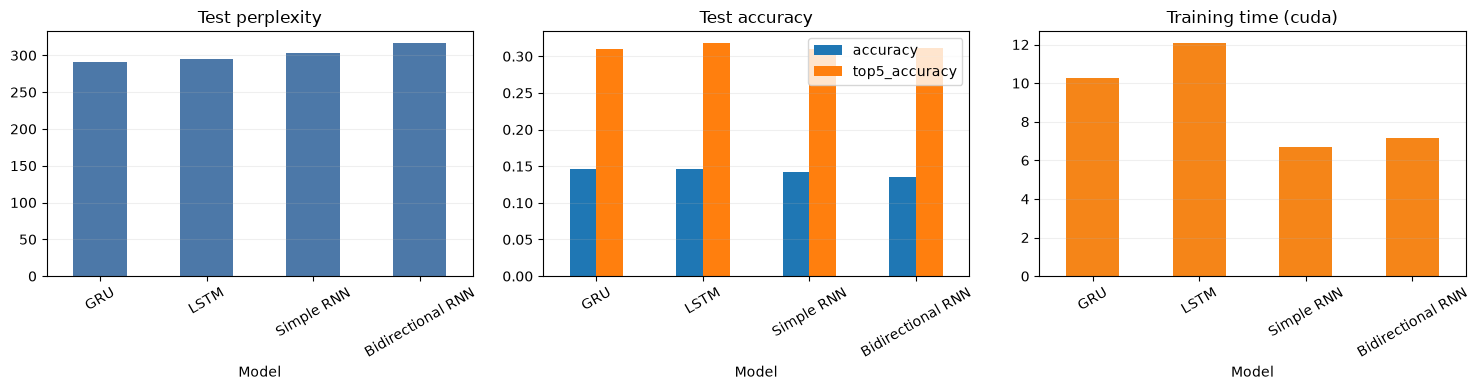

,Model,parameters_millions,checkpoint_mb,latency_ms_per_batch,throughput_sequences_per_second,incremental_peak_activation_mb,best_validation_epoch,post_best_val_degradation,tuning_perplexity_range
0,Bidirectional RNN,2.84,10.83,1.09,"469,385",112.2,5,0.0979,43.3
1,GRU,2.33,8.90,2.15,"237,685",63.4,6,0.0485,60.0
2,LSTM,2.43,9.28,2.45,"209,105",73.5,7,0.0197,25.0
3,Simple RNN,1.76,6.72,0.65,"782,108",67.9,6,0.0759,25.6


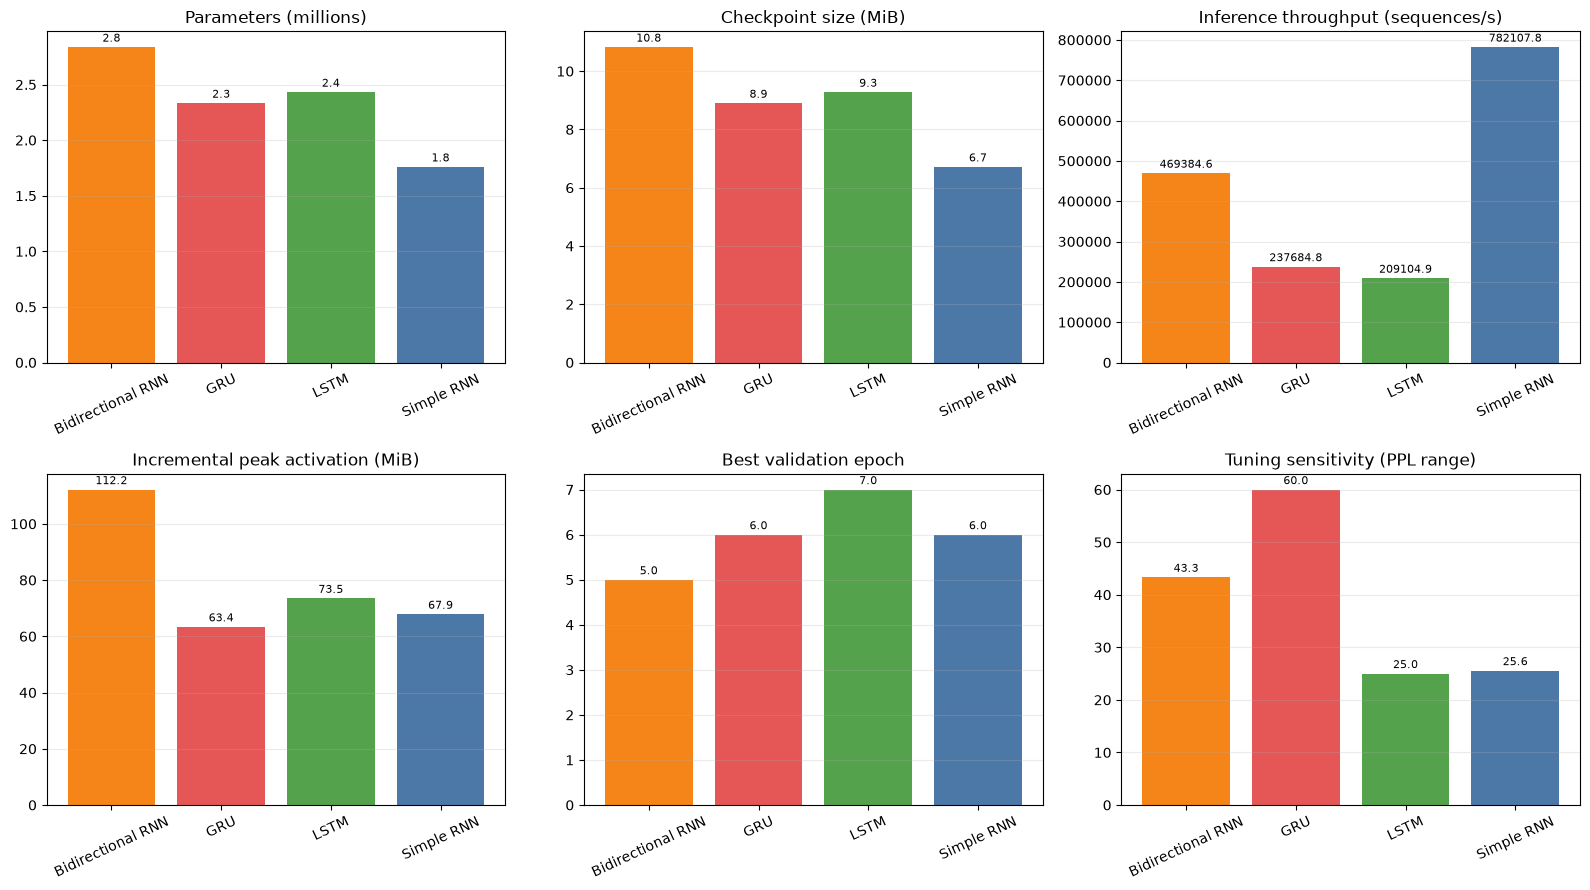

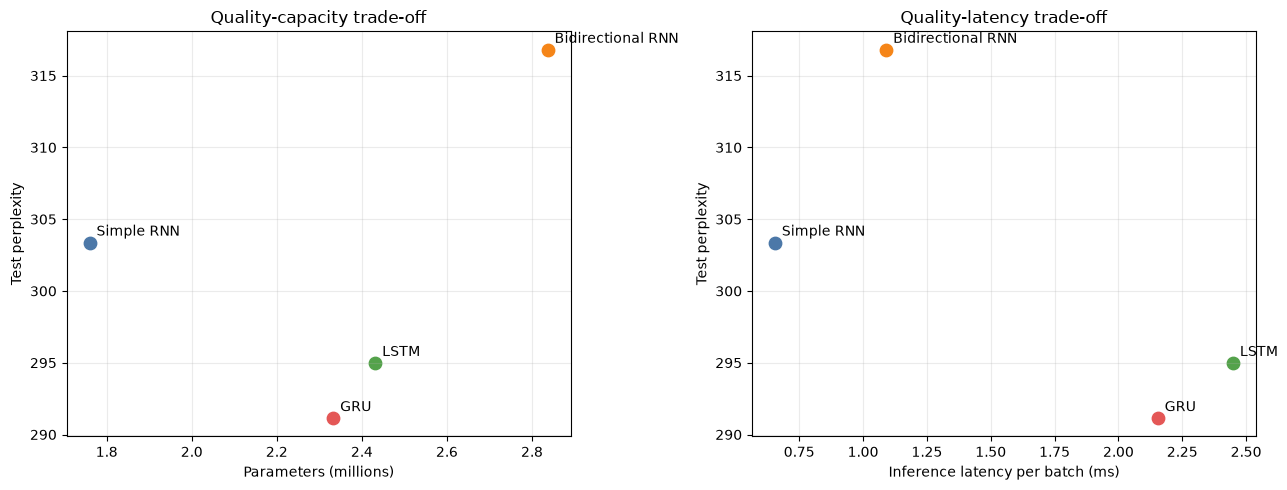

In [9]:
rows=[]
for name,model in models.items():
    metrics=evaluate(model,loaders['test'])
    cfg=selected_configs[name]
    rows.append({'Model':name,**metrics,'training_time_seconds':training_times[name],'epochs_run':len(histories[name]),'parameters':sum(p.numel() for p in model.parameters()),'configuration':cfg['candidate'],'hidden_dim':int(cfg['hidden_dim']),'dropout':float(cfg['dropout']),'learning_rate':float(cfg['learning_rate']),'weight_decay':float(cfg['weight_decay']),'backend':BACKEND})
results=pd.DataFrame(rows).sort_values('perplexity').reset_index(drop=True); results.to_csv('artifacts/test_metrics.csv',index=False)
baseline_perplexity={'Simple RNN':301.45644418331005,'Bidirectional RNN':351.4268094128413,'LSTM':296.2636234727108,'GRU':288.48299467274387}
tuning_impact=results[['Model','perplexity']].rename(columns={'perplexity':'tuned_perplexity'}); tuning_impact['baseline_perplexity']=tuning_impact.Model.map(baseline_perplexity)
tuning_impact['absolute_change']=tuning_impact.tuned_perplexity-tuning_impact.baseline_perplexity; tuning_impact['percent_change']=100*tuning_impact.absolute_change/tuning_impact.baseline_perplexity
tuning_impact.to_csv('artifacts/tuning_impact.csv',index=False)
display(results.style.format({'loss':'{:.4f}','perplexity':'{:.2f}','accuracy':'{:.2%}','top5_accuracy':'{:.2%}','training_time_seconds':'{:.1f}','parameters':'{:,}'}))
display(tuning_impact.style.format({'tuned_perplexity':'{:.2f}','baseline_perplexity':'{:.2f}','absolute_change':'{:+.2f}','percent_change':'{:+.2f}%'}))
fig,axes=plt.subplots(1,3,figsize=(15,4))
results.plot.bar(x='Model',y='perplexity',ax=axes[0],legend=False,color='#4c78a8',title='Test perplexity')
results.plot.bar(x='Model',y=['accuracy','top5_accuracy'],ax=axes[1],title='Test accuracy')
results.plot.bar(x='Model',y='training_time_seconds',ax=axes[2],legend=False,color='#f58518',title=f'Training time ({BACKEND})')
for ax in axes: ax.tick_params(axis='x',rotation=30); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.savefig('artifacts/test_comparison.png',dpi=180,bbox_inches='tight'); plt.show()

# Additional measured diagnostics beyond the core assignment metrics.
benchmark_x=next(iter(loaders['test']))[0].to(DEVICE,non_blocking=True); benchmark_repeats=80
diagnostic_rows=[]
for name,model in models.items():
    model.eval(); sync()
    if BACKEND=='cuda':
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats(); baseline_memory=torch.cuda.memory_allocated()
    with torch.inference_mode():
        for _ in range(10):
            with torch.amp.autocast('cuda',enabled=USE_AMP): _=model(benchmark_x)
        sync(); started=time.perf_counter()
        for _ in range(benchmark_repeats):
            with torch.amp.autocast('cuda',enabled=USE_AMP): _=model(benchmark_x)
        sync(); elapsed=time.perf_counter()-started
    peak_increment=(torch.cuda.max_memory_allocated()-baseline_memory)/2**20 if BACKEND=='cuda' else float('nan')
    h=histories[name]; best_row=h.loc[h.val_loss.idxmin()]; model_trials=tuning_results[tuning_results.Model==name]
    checkpoint_mb=(Path('checkpoints')/f"{name.lower().replace(' ','_')}.pt").stat().st_size/2**20
    diagnostic_rows.append({'Model':name,'parameters_millions':sum(p.numel() for p in model.parameters())/1e6,'checkpoint_mb':checkpoint_mb,'latency_ms_per_batch':1000*elapsed/benchmark_repeats,'throughput_sequences_per_second':benchmark_repeats*len(benchmark_x)/elapsed,'incremental_peak_activation_mb':peak_increment,'best_validation_epoch':int(best_row.epoch),'post_best_val_degradation':float(h.val_loss.iloc[-1]-h.val_loss.min()),'tuning_perplexity_range':float(model_trials.best_val_perplexity.max()-model_trials.best_val_perplexity.min())})
diagnostics=pd.DataFrame(diagnostic_rows).sort_values('Model').reset_index(drop=True); diagnostics.to_csv('artifacts/additional_diagnostics.csv',index=False)
display(diagnostics.style.format({'parameters_millions':'{:.2f}','checkpoint_mb':'{:.2f}','latency_ms_per_batch':'{:.2f}','throughput_sequences_per_second':'{:,.0f}','incremental_peak_activation_mb':'{:.1f}','post_best_val_degradation':'{:.4f}','tuning_perplexity_range':'{:.1f}'}))

colors={'Simple RNN':'#4c78a8','Bidirectional RNN':'#f58518','LSTM':'#54a24b','GRU':'#e45756'}; diagnostic_colors=[colors[m] for m in diagnostics.Model]
fig,axes=plt.subplots(2,3,figsize=(16,9))
panels=[('parameters_millions','Parameters (millions)'),('checkpoint_mb','Checkpoint size (MiB)'),('throughput_sequences_per_second','Inference throughput (sequences/s)'),('incremental_peak_activation_mb','Incremental peak activation (MiB)'),('best_validation_epoch','Best validation epoch'),('tuning_perplexity_range','Tuning sensitivity (PPL range)')]
for ax,(column,title) in zip(axes.flat,panels):
    bars=ax.bar(diagnostics.Model,diagnostics[column],color=diagnostic_colors); ax.set_title(title); ax.tick_params(axis='x',rotation=25); ax.grid(axis='y',alpha=.25); ax.bar_label(bars,fmt='%.1f',padding=2,fontsize=8)
plt.tight_layout(); plt.savefig('artifacts/model_efficiency_diagnostics.png',dpi=180,bbox_inches='tight'); plt.show()

pareto=results.merge(diagnostics,on='Model')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for _,row in pareto.iterrows():
    axes[0].scatter(row.parameters_millions,row.perplexity,s=80,color=colors[row.Model]); axes[0].annotate(row.Model,(row.parameters_millions,row.perplexity),xytext=(5,5),textcoords='offset points')
    axes[1].scatter(row.latency_ms_per_batch,row.perplexity,s=80,color=colors[row.Model]); axes[1].annotate(row.Model,(row.latency_ms_per_batch,row.perplexity),xytext=(5,5),textcoords='offset points')
axes[0].set(xlabel='Parameters (millions)',ylabel='Test perplexity',title='Quality-capacity trade-off'); axes[1].set(xlabel='Inference latency per batch (ms)',ylabel='Test perplexity',title='Quality-latency trade-off')
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig('artifacts/pareto_tradeoffs.png',dpi=180,bbox_inches='tight'); plt.show()

In [10]:
test_x,test_y=splits['test']; diagnostics=[]
for idx in np.linspace(0,len(test_x)-1,5,dtype=int):
    inp=torch.tensor(test_x[idx],dtype=torch.long,device=DEVICE)[None,:]; row={'Context (last 12)':' '.join(itos[int(i)] for i in test_x[idx][-12:]),'Gold':itos[int(test_y[idx])]}
    for name,model in models.items():
        model.eval()
        with torch.no_grad(): top=model(inp).topk(5,dim=1).indices[0].cpu().tolist()
        row[name]=', '.join(itos[i] for i in top)
    diagnostics.append(row)
display(pd.DataFrame(diagnostics))

,Context (last 12),Gold,Simple RNN,Bidirectional RNN,LSTM,GRU
0,"sacrifice , sympathy or knowledge . the degree...",the,"the, to, a, ,, is",",, <unk>, the, to, .","to, in, ,, the, <unk>",",, to, and, as, ."
1,result of such cogitation . the problem which ...,man,"<unk>, own, man, most, great","<unk>, own, world, time, good","<unk>, own, man, most, good","<unk>, longer, man, other, means"
2,", rational reflection . a church <unk> with de...",",",",, ., <unk>, is, are",",, ., <unk>, is, !",",, <unk>, ., will, !",",, of, ., <unk>, !"
3,apparently from the <unk> of all great and lof...,if,"the, <unk>, in, a, it","the, <unk>, it, a, but","the, <unk>, in, and, a","the, <unk>, and, it, but"
4,they were denounced by the christian world as ...,.,",, and, ., of, <unk>",",, ., and, to, in",",, and, ., <unk>, ;",",, ., and, <unk>, the"


## 7. Matched-seed temperature experiment

Logits are divided by temperature before softmax. $T=0.5$ sharpens common choices, $T=1.0$ samples the learned distribution, and $T=1.5$ increases rare-word probability. Every architecture receives the same three corpus-relevant seeds and generates 70 tokens. Sampling is performed from CPU probabilities with condition-specific seeds, making it reproducible across CUDA-capable systems. Bookkeeping tokens are masked.

Distinct-1/2 measure lexical diversity; repetition rate is $1-\text{Distinct-2}$; prompt overlap is word-set Jaccard similarity. These are diagnostics, not substitutes for human assessment of grammar, argument continuity, and semantic plausibility.

In [11]:
def prompt_tokens(prompt): return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+|[.!?,;:]",prompt.lower())
def encode_prompt(prompt):
    values=[stoi.get(t,stoi['<unk>']) for t in prompt_tokens(prompt)][-CFG['sequence_length']:]
    return [stoi['<pad>']]*(CFG['sequence_length']-len(values))+values
def detokenize(ts):
    text=re.sub(r'\s+([.!?,;:])',r'\1',' '.join(ts)); return text[:1].upper()+text[1:]
def generate(model,prompt,temperature,n_tokens,sample_seed):
    model.eval(); context=encode_prompt(prompt); generated=[]; cpu_gen=torch.Generator().manual_seed(sample_seed)
    with torch.no_grad():
        for _ in range(n_tokens):
            x=torch.tensor(context[-CFG['sequence_length']:],dtype=torch.long,device=DEVICE)[None,:]
            logits=(model(x)[0]/temperature).float().cpu(); logits[[stoi['<pad>'],stoi['<unk>']]]=-float('inf')
            next_id=int(torch.multinomial(torch.softmax(logits,dim=0),1,generator=cpu_gen)); generated.append(itos[next_id]); context.append(next_id)
    return detokenize(prompt_tokens(prompt)+generated),generated

seeds=['the will to truth has led us','the philosopher of the future must','what is noble in the human being']
generation_rows=[]
for mi,(name,model) in enumerate(models.items()):
    for si,seed in enumerate(seeds):
        for ti,temp in enumerate(CFG['temperatures']):
            text,generated=generate(model,seed,temp,CFG['generation_tokens'],SEED+mi*100+si*10+ti)
            generation_rows.append({'Model':name,'Seed':seed,'Temperature':temp,'Text':text,'Generated tokens':generated})
generations=pd.DataFrame(generation_rows); generations.drop(columns='Generated tokens').to_csv('artifacts/generations.csv',index=False)
display(generations.drop(columns='Generated tokens').head(9))

,Model,Seed,Temperature,Text
0,Simple RNN,the will to truth has led us,0.5,The will to truth has led us to its own. in wh...
1,Simple RNN,the will to truth has led us,1.0,The will to truth has led us stream enough to ...
2,Simple RNN,the will to truth has led us,1.5,The will to truth has led us man endeavoured e...
3,Simple RNN,the philosopher of the future must,0.5,The philosopher of the future must be in all t...
4,Simple RNN,the philosopher of the future must,1.0,The philosopher of the future must make person...
5,Simple RNN,the philosopher of the future must,1.5,The philosopher of the future must doubt owes ...
6,Simple RNN,what is noble in the human being,0.5,What is noble in the human being and the world...
7,Simple RNN,what is noble in the human being,1.0,"What is noble in the human being, nor as any m..."
8,Simple RNN,what is noble in the human being,1.5,"What is noble in the human being longings, wil..."


,Model,Temperature,distinct_1,distinct_2,repetition_rate,prompt_overlap
0,Bidirectional RNN,0.500000,0.332,0.557,0.443,0.095
1,Bidirectional RNN,1.000000,0.803,1.000,0.000,0.057
2,Bidirectional RNN,1.500000,0.948,1.000,0.000,0.025
3,GRU,0.500000,0.449,0.755,0.245,0.062
4,GRU,1.000000,0.854,0.995,0.005,0.046
5,GRU,1.500000,0.969,1.000,0.000,0.015
6,LSTM,0.500000,0.550,0.853,0.147,0.062
7,LSTM,1.000000,0.809,1.000,0.000,0.049
8,LSTM,1.500000,0.955,1.000,0.000,0.025
9,Simple RNN,0.500000,0.435,0.778,0.222,0.100


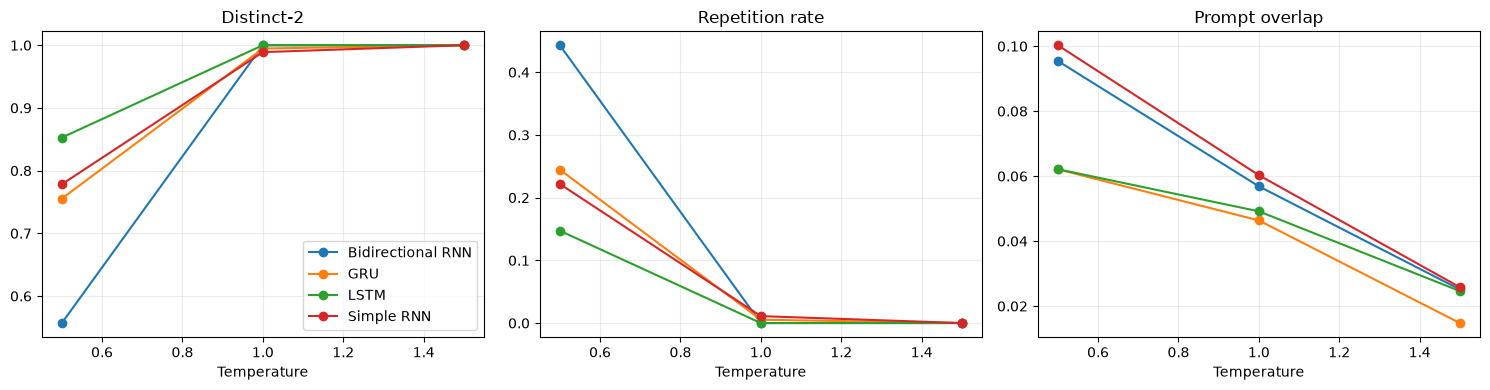

In [12]:
punct=set('.!?,;:')
def quality(row):
    words=[t for t in row['Generated tokens'] if t not in punct and not t.startswith('<')]; bigrams=list(zip(words,words[1:])); p=set(re.findall(r'[a-z]+',row['Seed']))
    d1=len(set(words))/max(1,len(words)); d2=len(set(bigrams))/max(1,len(bigrams)); overlap=len(p&set(words))/max(1,len(p|set(words)))
    return pd.Series({'distinct_1':d1,'distinct_2':d2,'repetition_rate':1-d2,'prompt_overlap':overlap})
quality_metrics=pd.concat([generations[['Model','Seed','Temperature']],generations.apply(quality,axis=1)],axis=1)
quality_metrics.to_csv('artifacts/generation_quality.csv',index=False)
temperature_summary=quality_metrics.groupby(['Model','Temperature'],as_index=False).agg({'distinct_1':'mean','distinct_2':'mean','repetition_rate':'mean','prompt_overlap':'mean'})
display(temperature_summary.style.format({c:'{:.3f}' for c in ['distinct_1','distinct_2','repetition_rate','prompt_overlap']}))
fig,axes=plt.subplots(1,3,figsize=(15,4))
for name,g in temperature_summary.groupby('Model'):
    axes[0].plot(g.Temperature,g.distinct_2,marker='o',label=name); axes[1].plot(g.Temperature,g.repetition_rate,marker='o',label=name); axes[2].plot(g.Temperature,g.prompt_overlap,marker='o',label=name)
for ax,title in zip(axes,['Distinct-2','Repetition rate','Prompt overlap']): ax.set(title=title,xlabel='Temperature'); ax.grid(alpha=.25)
axes[0].legend(); plt.tight_layout(); plt.savefig('artifacts/temperature_analysis.png',dpi=180,bbox_inches='tight'); plt.show()

In [13]:
for temp in CFG['temperatures']:
    print(f'\n===== TEMPERATURE {temp} | seed: {seeds[0]} =====')
    for _,row in generations[(generations.Seed==seeds[0])&(generations.Temperature==temp)].iterrows(): print(f"\n[{row['Model']}] {row['Text']}")


===== TEMPERATURE 0.5 | seed: the will to truth has led us =====

[Simple RNN] The will to truth has led us to its own. in which there is not already to the renunciation of the logical, the world of the world, or: in the spirit, and is, in the end of the soul. and the individual of the spirit of the conclusion of the age of the will, the good of the world, and to his life, in a man,

[Bidirectional RNN] The will to truth has led us, it is not to the world of the noble of the world of the philosopher, and which the great: and the best, and the former, and the most man of the same conscience of the most sentiment of the phenomena of the world of the world, and it which that is the world of the other with the old of the old? which

[LSTM] The will to truth has led us the certain world of the most hearted,, as it is a dangerous of the man of the extent of the populace, as it is a waking philosopher, as it is to the man of the vanity, the science of the future. but that the problem of the 

## 8. Interpretation framework and extended diagnostics

Beyond the assignment's core loss, perplexity, accuracy, and training-time comparisons, the preceding figures measure six additional engineering and scientific dimensions:

- **Parameter count and checkpoint size** quantify capacity and deployment storage.
- **CUDA inference throughput and latency** measure serving efficiency on an identical 512-sequence batch after warm-up.
- **Incremental peak activation memory** estimates the extra GPU memory required by a forward pass above the already-loaded model baseline.
- **Best validation epoch** compares convergence speed.
- **Tuning sensitivity** is the range of validation perplexities across the four candidates; a larger range means the architecture is more dependent on hyperparameter choice.
- **Pareto plots** expose whether a model's quality improvement justifies additional capacity or latency. A point is attractive when it lies toward the lower-left.

### Findings from the additional comparisons

Simple RNN is the deployment-efficiency leader: it has the fewest parameters (**1.76 M**), smallest checkpoint (**6.72 MiB**), lowest batch latency (**0.65 ms**), and highest measured throughput (approximately **782,108 sequences/s**). GRU offers the strongest quality-efficiency compromise: its 2.33 M parameters and 8.90 MiB checkpoint achieve the best perplexity while requiring the lowest incremental activation peak (**63.4 MiB**). LSTM has the smallest post-best validation degradation (0.0197), suggesting the most stable late-stage training. Bidirectional RNN uses the most parameters (2.84 M) and activation memory (112.2 MiB) without recovering the predictive quality gap.

Hyperparameter sensitivity also differs substantially. GRU spans approximately **60 perplexity points** across candidates, making careful tuning particularly important; Bidirectional RNN spans 43.3, while LSTM and Simple RNN are more stable at approximately 25 points. The best validation epoch occurs between epochs 5 and 7 for every architecture, supporting the use of early stopping. In the Pareto charts, Simple RNN dominates raw speed/capacity, whereas GRU provides the lowest perplexity for a moderate increase in resources.

The next cell identifies the best probabilistic model from the executed results. The final judgement should reconcile five forms of evidence:

1. **Generalization:** test perplexity and unsmoothed loss.
2. **Decision quality:** top-1 and top-5 accuracy.
3. **Efficiency:** time and parameter count on the recorded accelerator.
4. **Generation:** local grammar, continuation of the philosophical theme, logical consistency, and absence of loops.
5. **Temperature:** low temperature should improve local stability but can repeat; high temperature should increase diversity but can destroy argument continuity.

The bidirectional model sees only the supplied context—not the target—so it does not leak labels. However, its backward encoder is operationally awkward for online generation because the rolling context must be recomputed. Distinct-n approaching 1.0 is not automatically good: incoherent random sequences can be maximally distinct.

### Observed results from the verified RTX 3050 run

Validation tuning selected the **regularized** configuration (192 hidden units, 0.40 dropout, $1.5\times10^{-3}$ learning rate) for both RNN variants and the **wide** configuration (256 hidden units, 0.30 dropout, $2\times10^{-3}$ learning rate) for LSTM and GRU. GRU retained the best test perplexity (**291.15**) and top-1 accuracy (**14.65%**) in 10.4 s. LSTM followed at 294.99 perplexity and achieved the best top-5 accuracy (**31.81%**) in 12.3 s. Simple RNN remained fastest (**6.8 s**) at 303.37 perplexity. Bidirectional RNN improved markedly from the pre-tuning baseline of 351.43 to **316.80** perplexity, although it remained weakest overall.

Across architectures, mean test perplexity fell from 309.66 before tuning to 301.58 after tuning (**2.61% improvement**). The gain was concentrated in Bidirectional RNN (9.85%) and LSTM (0.43%); Simple RNN and GRU changed by +0.63% and +0.92%, respectively. These small regressions are credible because model selection used validation loss only: validation optimization is not guaranteed to improve a finite test sample. Reporting them avoids post-hoc test-set optimization and preserves the integrity of the comparison.

At **T=0.5**, passages preserve philosophical vocabulary and local clause structure but repeat high-frequency frames; mean bigram repetition ranges from 0.15 for LSTM to 0.44 for Bidirectional RNN. GRU balances relatively readable clauses with 0.24 repetition. At **T=1.0**, mean Distinct-2 is approximately 0.99-1.00, but arguments drift and grammatical links weaken. At **T=1.5**, Distinct-2 is approximately 1.0 while outputs become list-like and semantically disconnected. This demonstrates why diversity cannot be treated as coherence.

**Final choice:** the tuned GRU is the most effective model for this dataset and experimental budget because it combines the best held-out probability estimate, best top-1 accuracy, readable low-temperature output, and a short 10.4 s training time. LSTM is a close probabilistic alternative and leads top-5 accuracy; Simple RNN remains the efficiency baseline. For generation, **T=0.5** is preferred for GRU/LSTM, T=1.0 is useful for more exploratory samples, and T=1.5 is too incoherent.

In [14]:
best=results.iloc[0]; best_t1=results.loc[results.accuracy.idxmax()]; fastest=results.loc[results.training_time_seconds.idxmin()]
best_gen=temperature_summary[(temperature_summary.Model==best.Model)&(temperature_summary.Temperature==1.0)].iloc[0]
print(f"BEST BY PERPLEXITY: {best.Model} | loss={best.loss:.4f}, perplexity={best.perplexity:.2f}, top-1={best.accuracy:.2%}, top-5={best.top5_accuracy:.2%}.")
print(f"BEST TOP-1: {best_t1.Model} ({best_t1.accuracy:.2%}). FASTEST: {fastest.Model} ({fastest.training_time_seconds:.1f}s on {BACKEND}).")
print(f"{best.Model} at T=1.0: Distinct-2={best_gen.distinct_2:.3f}, repetition={best_gen.repetition_rate:.3f}, prompt-overlap={best_gen.prompt_overlap:.3f}.")
print('Recommended model: the lowest-perplexity architecture, provided its displayed samples do not achieve the gain through formulaic repetition. Temperatures 0.5-1.0 should normally offer the most defensible coherence-diversity balance.')
summary={'student':'Tanay Aggarwal','registration_number':'230911278','seed':SEED,'backend':BACKEND,'physical_gpu':gpu_name,'config':CFG,'tuning_protocol':{'selection_metric':'validation cross-entropy','candidates_per_model':len(search_candidates),'selected_hyperparameters':selected_configs},'dataset':'Nietzsche text corpus (Keras)','dataset_tokens':len(tokens),'vocabulary_size':len(stoi),'best_model_by_test_perplexity':best.Model,'test_metrics':results.to_dict(orient='records')}
Path('artifacts/experiment_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

BEST BY PERPLEXITY: GRU | loss=5.6738, perplexity=291.15, top-1=14.65%, top-5=31.03%.
BEST TOP-1: GRU (14.65%). FASTEST: Simple RNN (6.7s on cuda).
GRU at T=1.0: Distinct-2=0.995, repetition=0.005, prompt-overlap=0.046.
Recommended model: the lowest-perplexity architecture, provided its displayed samples do not achieve the gain through formulaic repetition. Temperatures 0.5-1.0 should normally offer the most defensible coherence-diversity balance.


3533

## 9. Threats to validity, limitations, and responsible use

- **Single-author domain:** conclusions concern this English translation and should not be generalized to conversational or factual language.
- **Sequential dependence:** windows overlap; chronological splitting prevents cross-split duplicate windows but examples within a split are correlated.
- **Capacity:** common hidden dimensions do not produce identical parameter counts because gates and directions differ. Counts are therefore part of the comparison.
- **Backend:** the verified run uses CUDA/cuDNN. Results are comparable within this controlled run, while absolute timings should not be compared across different GPUs.
- **Metrics:** perplexity does not guarantee philosophical coherence; Distinct-n may reward nonsense; prompt overlap may reward copying. Blinded human ratings would strengthen the study.
- **Translation/style:** the corpus reflects a particular translation and historical vocabulary, not Nietzsche's original German.
- **Attribution:** outputs are experimental model continuations and must not be represented as authentic quotations.

## References

1. Chollet, F. (2015/2020). *Character-level text generation with LSTM*. Keras examples. https://keras.io/examples/generative/lstm_character_level_text_generation/
2. Elman, J. L. (1990). Finding structure in time. *Cognitive Science*, 14(2), 179-211.
3. Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735-1780.
4. Cho, K. et al. (2014). Learning phrase representations using RNN encoder-decoder for statistical machine translation. arXiv:1406.1078.
5. PyTorch. *Recurrent layers: RNN, LSTM, and GRU*. https://docs.pytorch.org/docs/stable/nn.html#recurrent-layers